<img src="MUML_header.svg" alt="Header" style="width:100%; height:auto;">

In [1]:
import torch
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm

In this exercise, you will implement several optimization algorithms from scratch using PyTorch tensors, and compare their behavior on the Rosenbrock function, a classical non-convex test function for optimization.

The Rosenbrock function in 2D is defined as:

$$f(x,y)=(1-x)^2+100(y-x^2)^2$$

It has a global minimum at $(x,y)=(1,1)$ with value $f(1,1)=0$.

However, it is notoriously difficult to optimize because of its narrow, curved valley.

In [2]:
def rosenbrock(p):
    x, y = p[0], p[1]
    return (1 - x)**2 + 100.0 * (y - x**2)**2

Before optimizing, we plot the contours of the function.

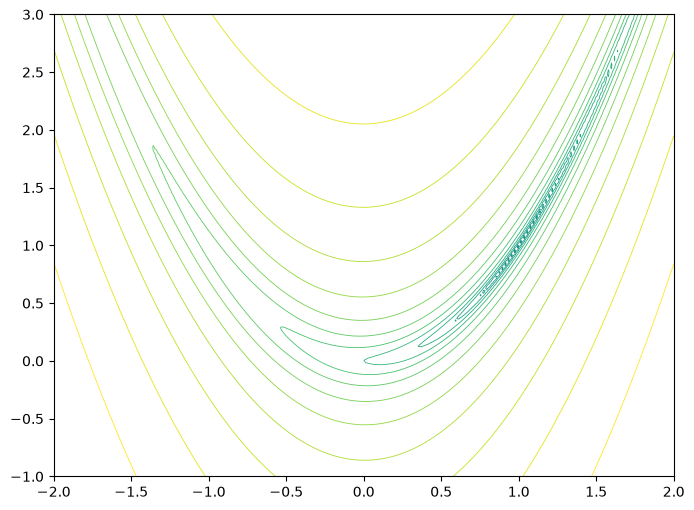

In [3]:
xlim, ylim = (-2.0, 2.0), (-1.0, 3.0)
nx, ny = 200, 200
xs = np.linspace(xlim[0], xlim[1], nx); ys = np.linspace(ylim[0], ylim[1], ny)
X,Y = np.meshgrid(xs, ys); Z = np.zeros_like(X)
for i in range(nx):
    for j in range(ny):
        pt = torch.tensor([X[j,i], Y[j,i]], dtype=torch.get_default_dtype())
        Z[j,i] = rosenbrock(pt).item()

plt.figure(figsize=(8,6))
levels = np.logspace(-6, 3, 25)
plt.contour(X, Y, Z, levels=levels, norm=LogNorm(), linewidths=0.6)

You will implement the studied optimizers as Python classes with a `step(params, grads)` method. Each class should keep track of its internal state (velocity, squared gradients, etc.).
* SGD with momentum
* Adagrad
* RMSProp
* Adadelta
* Adam

In [4]:
import torch

class SGDWithMomentum:
    def __init__(self, lr=0.001, momentum=0.9):
        self.lr = lr
        self.momentum = momentum
        self.v = None

    def step(self, params, grads):
        if self.v is None:
            self.v = torch.zeros_like(params)
        
        self.v = self.momentum * self.v + self.lr * grads
        return params - self.v


class Adagrad:
    def __init__(self, lr=0.1, eps=1e-8):
        self.lr = lr
        self.eps = eps
        self.s = None

    def step(self, params, grads):
        if self.s is None:
            self.s = torch.zeros_like(params)
        
        self.s += grads ** 2
        return params - (self.lr / (torch.sqrt(self.s) + self.eps)) * grads


class RMSProp:
    def __init__(self, lr=0.01, beta=0.9, eps=1e-8):
        self.lr = lr
        self.beta = beta
        self.eps = eps
        self.s = None

    def step(self, params, grads):
        if self.s is None:
            self.s = torch.zeros_like(params)
        
        self.s = self.beta * self.s + (1.0 - self.beta) * (grads ** 2)
        return params - (self.lr / (torch.sqrt(self.s) + self.eps)) * grads


class Adadelta:
    def __init__(self, rho=0.9, eps=1e-6):
        self.rho = rho
        self.eps = eps
        self.v_g = None 
        self.v_x = None  

    def step(self, params, grads):
        if self.v_g is None:
            self.v_g = torch.zeros_like(params)
            self.v_x = torch.zeros_like(params)

        self.v_g = self.rho * self.v_g + (1.0 - self.rho) * (grads ** 2)
        
        rms_g = torch.sqrt(self.v_g + self.eps)
        rms_x = torch.sqrt(self.v_x + self.eps)
        delta_x = - (rms_x / rms_g) * grads
        
        self.v_x = self.rho * self.v_x + (1.0 - self.rho) * (delta_x ** 2)

        return params + delta_x


class Adam:
    def __init__(self, lr=0.001, beta1=0.9, beta2=0.999, eps=1e-8):
        self.lr = lr
        self.beta1 = beta1
        self.beta2 = beta2
        self.eps = eps
        self.m = None  
        self.v = None  
        self.t = 0    

    def step(self, params, grads):
        if self.m is None:
            self.m = torch.zeros_like(params)
            self.v = torch.zeros_like(params)

        self.t += 1
        
        self.m = self.beta1 * self.m + (1.0 - self.beta1) * grads
        self.v = self.beta2 * self.v + (1.0 - self.beta2) * (grads ** 2)

        m_hat = self.m / (1.0 - self.beta1 ** self.t)
        v_hat = self.v / (1.0 - self.beta2 ** self.t)

        return params - self.lr * m_hat / (torch.sqrt(v_hat) + self.eps)

Run the experiments. Choose an initial point (e.g. [-1.5, 1.5]) and adjust the needed parameters for each optimizer. Run each optimizer for ~2000 iterations. Record the trajectory (sequence of (x,y)) and the loss values.

In [5]:
start_pt = torch.tensor([-1.5, 1.5])
num_iterations = 2000

# Hyperparameters tuned specifically for the steep valley of Rosenbrock
optimizers = {
    "SGD + Momentum (lr=0.001)": SGDWithMomentum(lr=0.001, momentum=0.9),
    "Adagrad (lr=0.2)":          Adagrad(lr=0.2),
    "RMSProp (lr=0.005)":        RMSProp(lr=0.005, beta=0.9),
    "Adadelta (rho=0.95)":       Adadelta(rho=0.95),
    "Adam (lr=0.02)":            Adam(lr=0.02, beta1=0.9, beta2=0.999)
}

results = {}

for name, opt in optimizers.items():
    p = start_pt.clone().detach().requires_grad_(True)
    traj = [p.detach().numpy().copy()]
    losses = []

    for _ in range(num_iterations):
        loss = rosenbrock(p)
        losses.append(loss.item())
        
        loss.backward()

        with torch.no_grad():
            p_new = opt.step(p, p.grad)
            p.copy_(p_new)
            p.grad.zero_()

        traj.append(p.detach().numpy().copy())

    results[name] = {
        "trajectory": np.array(traj),
        "losses": np.array(losses),
        "final_point": p.detach().numpy().copy(),
        "final_loss": losses[-1]
    }

Plot the trajectories of each optimizer on top of the Rosenbrock contour plot. Besides, plot loss vs iteration (use a log scale on the y-axis).

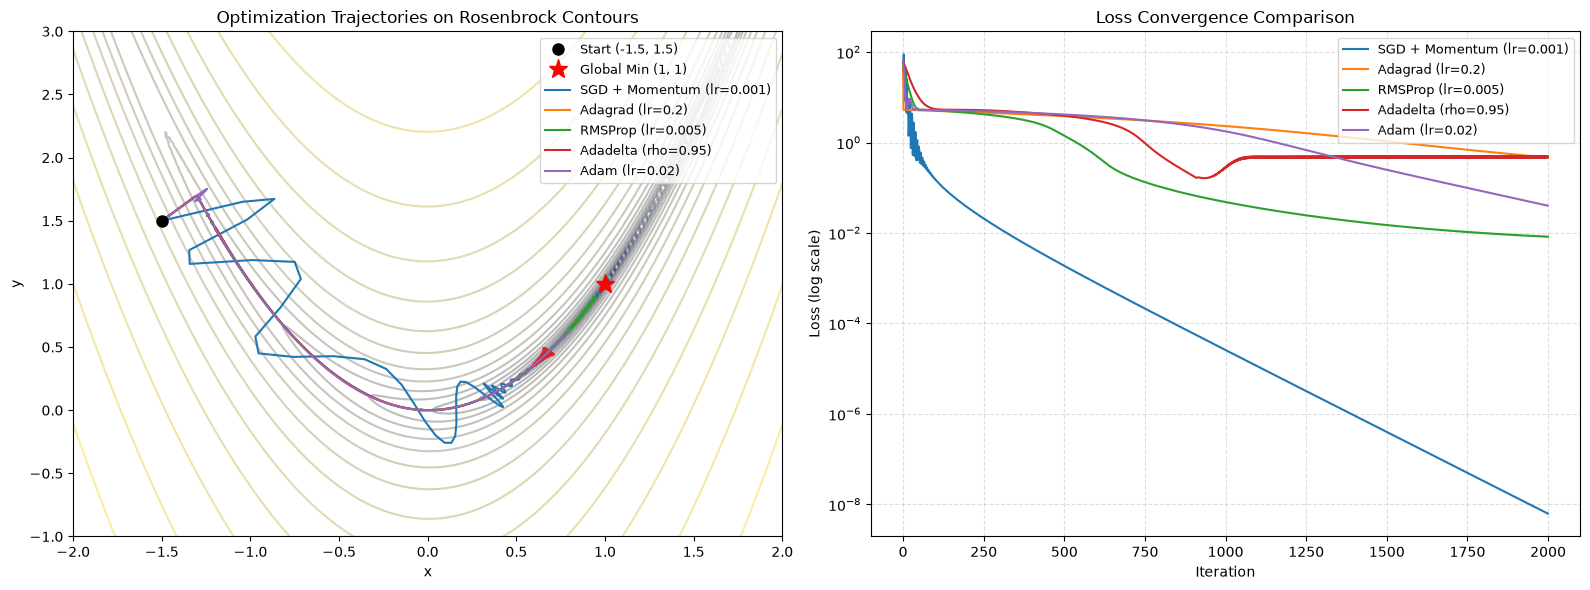

In [6]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# Subplot 1: Optimizer Trajectories on Rosenbrock Contour Map
levels = np.logspace(-3, 3.5, 25)
contour = ax1.contour(X, Y, Z, levels=levels, norm=LogNorm(), cmap="cividis", alpha=0.5)
ax1.plot(start_pt[0], start_pt[1], 'ko', markersize=8, label="Start (-1.5, 1.5)", zorder=5)
ax1.plot(1.0, 1.0, 'r*', markersize=14, label="Global Min (1, 1)", zorder=5)

for name, res in results.items():
    traj = res["trajectory"]
    ax1.plot(traj[:, 0], traj[:, 1], label=name, linewidth=1.5)

ax1.set_xlim(xlim)
ax1.set_ylim(ylim)
ax1.set_xlabel("x")
ax1.set_ylabel("y")
ax1.set_title("Optimization Trajectories on Rosenbrock Contours")
ax1.legend(loc="upper right", fontsize=9)

# Subplot 2: Loss vs. Iteration (Logarithmic Scale)
for name, res in results.items():
    ax2.plot(res["losses"], label=name, linewidth=1.5)

ax2.set_yscale("log")
ax2.set_xlabel("Iteration")
ax2.set_ylabel("Loss (log scale)")
ax2.set_title("Loss Convergence Comparison")
ax2.grid(True, which="both", linestyle="--", alpha=0.4)
ax2.legend(loc="upper right", fontsize=9)

plt.tight_layout()
plt.show()

Print the final parameters and final loss for each optimizer.

In [7]:

print(f"{'Optimizer':<28} | {'Final Point (x, y)':<22} | {'Final Loss':<12}")
print("-" * 68)

for name, opt in optimizers.items():
    p = start_pt.clone().detach().requires_grad_(True)
    
    for _ in range(num_iterations):
        loss = rosenbrock(p)
        loss.backward()

        with torch.no_grad():
            p_new = opt.step(p, p.grad)
            p.copy_(p_new)
            p.grad.zero_()

    final_x, final_y = p[0].item(), p[1].item()
    final_loss = loss.item()

    print(f"{name:<28} | ({final_x:8.5f}, {final_y:8.5f})   | {final_loss:.6e}")

Optimizer                    | Final Point (x, y)     | Final Loss  
--------------------------------------------------------------------
SGD + Momentum (lr=0.001)    | ( 0.99992,  0.99984)   | 6.268706e-09
Adagrad (lr=0.2)             | (-0.14812,  0.02307)   | 1.319835e+00
RMSProp (lr=0.005)           | ( 0.94250,  0.89536)   | 8.248681e-03
Adadelta (rho=0.95)          | ( 0.63541,  0.47109)   | 5.518305e-01
Adam (lr=0.02)               | ( 0.87089,  0.75806)   | 1.674241e-02
